#Felix Musyoka Mumo ; CS-sa06-24018
# Assignment 7: Linear Regression Practical Project — House Price Prediction

**Goal:** predict house `price` from property characteristics using multiple linear regression in Scikit-learn, following the three-stage structure:

1. **Explore Dataset** — load, inspect, clean and visualise the data
2. **Build Model** — prepare features, split the data and fit a `LinearRegression` model
3. **Test Model** — evaluate with MSE, RMSE and R², and check the linear regression assumptions (linearity, no multicollinearity, normal and independent errors, homoscedasticity)

**Dataset:** `homeprices.csv` — 100 houses, 8 columns: `area` (sq ft), `bedrooms`, `bathrooms`, `age` (years), `location_score` (0–10), `garage_type`, `condition`, `price` (target).

## 0. Setup

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
RANDOM_STATE = 42

def trend_line(ax, x, y, window=15, **kw):
    # moving-average trend of y against x (simple smoother for diagnostic plots)
    order = np.argsort(np.asarray(x))
    xs = np.asarray(x)[order]
    ys = pd.Series(np.asarray(y)[order]).rolling(window, center=True, min_periods=5).mean()
    ax.plot(xs, ys, lw=2.5, **kw)

In [2]:
# In Google Colab: upload homeprices.csv when prompted (skipped if the file is already present)
if not os.path.exists("homeprices.csv"):
    from google.colab import files
    files.upload()

Saving homeprices.csv to homeprices.csv


---
# Stage 1 — Explore Dataset

## 1.1 Load the data



In [3]:
df_raw = pd.read_csv("homeprices.csv", keep_default_na=False, na_values=[""])
print("Shape:", df_raw.shape)
df_raw.head(10)

Shape: (100, 8)


,area,bedrooms,bathrooms,age,location_score,garage_type,condition,price
0,3974,4,1.00,34.00,6.70,Attached,Excellent,809013
1,4307,1,2.00,79.00,2.70,Detached,Fair,669331
2,1660,5,NaN,60.00,1.60,Attached,Good,333718
3,2094,5,2.00,40.00,4.60,Attached,Poor,488932
4,1930,2,2.00,99.00,1.50,Attached,Fair,249520
5,12000,8,6.00,32.00,9.00,Detached,Fair,4500000
6,3892,2,2.00,67.00,1.20,Attached,Fair,555429
7,2438,1,3.00,32.00,6.20,Detached,Excellent,597270
8,2969,4,1.00,13.00,4.90,None,Good,602407
9,1266,4,1.00,20.00,7.00,Attached,Good,410356


## 1.2 Structure, data types and summary statistics

In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area            100 non-null    int64  
 1   bedrooms        100 non-null    int64  
 2   bathrooms       95 non-null     float64
 3   age             92 non-null     float64
 4   location_score  100 non-null    float64
 5   garage_type     100 non-null    object 
 6   condition       100 non-null    object 
 7   price           100 non-null    object 
dtypes: float64(3), int64(2), object(3)
memory usage: 6.4+ KB


In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
area,100.00,"2,866.51","1,400.07",821.00,"1,929.75","2,864.50","3,707.75","12,000.00"
bedrooms,100.00,3.19,2.29,1.00,1.75,3.00,4.00,20.00
bathrooms,95.00,2.04,0.91,1.00,1.00,2.00,3.00,6.00
age,92.00,50.22,30.39,1.00,26.75,47.00,67.25,150.00
location_score,100.00,5.29,2.72,1.10,2.70,5.05,7.45,9.80


In [6]:
for col in ["garage_type", "condition"]:
    print(f"{col}:\n{df_raw[col].value_counts(dropna=False)}\n")

garage_type:
garage_type
Attached    50
Detached    38
None         8
Street       3
detached     1
Name: count, dtype: int64

condition:
condition
Good         47
Fair         21
Excellent    18
Poor         14
Name: count, dtype: int64



In [7]:
# price should be numeric but was read as text - find the values that are not plain numbers
bad_price = df_raw[~df_raw["price"].astype(str).str.fullmatch(r"\d+(\.\d+)?")]
bad_price

,area,bedrooms,bathrooms,age,location_score,garage_type,condition,price
25,3233,1,2.00,53.00,2.70,Attached,Poor,"$550,000"


## 1.3 Missing values and duplicates

In [8]:
missing = pd.DataFrame({"missing": df_raw.isna().sum(),
                        "percent": (df_raw.isna().mean() * 100).round(1)})
print(missing)
print("\nDuplicate rows:", df_raw.duplicated().sum())

                missing  percent
area                  0     0.00
bedrooms              0     0.00
bathrooms             5     5.00
age                   8     8.00
location_score        0     0.00
garage_type           0     0.00
condition             0     0.00
price                 0     0.00

Duplicate rows: 0


**Data quality issues found:**

| Issue | Detail | Fix |
|---|---|---|
| `price` stored as text | one value written as `"$550,000"` | strip `$` and `,`, convert to float |
| Inconsistent category labels | `"detached"` vs `"Detached"` in `garage_type` | standardise capitalisation |
| Missing values | `bathrooms` (5), `age` (8) | impute with the median (robust to skew/outliers) |
| Suspicious extreme rows | see outlier check below | investigate and remove if not credible |

## 1.4 Cleaning

In [9]:
df = df_raw.copy()

# 1. price: text -> number
df["price"] = df["price"].astype(str).str.replace(r"[\$,]", "", regex=True).astype(float)

# 2. consistent category labels
df["garage_type"] = df["garage_type"].str.strip().str.title()

print(df.dtypes)
print("\ngarage_type:", df["garage_type"].value_counts().to_dict())

area                int64
bedrooms            int64
bathrooms         float64
age               float64
location_score    float64
garage_type        object
condition          object
price             float64
dtype: object

garage_type: {'Attached': 50, 'Detached': 39, 'None': 8, 'Street': 3}


### Outlier check (IQR rule: below Q1 − 1.5·IQR or above Q3 + 1.5·IQR)

In [10]:
num_cols = ["area", "bedrooms", "bathrooms", "age", "location_score", "price"]
outlier_rows = set()
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    idx = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)].index.tolist()
    outlier_rows.update(idx)
    print(f"{col:15s} outlier rows: {idx}")

df.loc[sorted(outlier_rows)]

area            outlier rows: [5]
bedrooms        outlier rows: [5, 15]
bathrooms       outlier rows: []
age             outlier rows: [42]
location_score  outlier rows: []
price           outlier rows: [5, 15, 42]


,area,bedrooms,bathrooms,age,location_score,garage_type,condition,price
5,12000,8,6.00,32.00,9.00,Detached,Fair,"4,500,000.00"
15,3971,20,NaN,NaN,3.30,Detached,Fair,"120,000.00"
42,3547,3,3.00,150.00,9.20,Attached,Poor,"45,000.00"


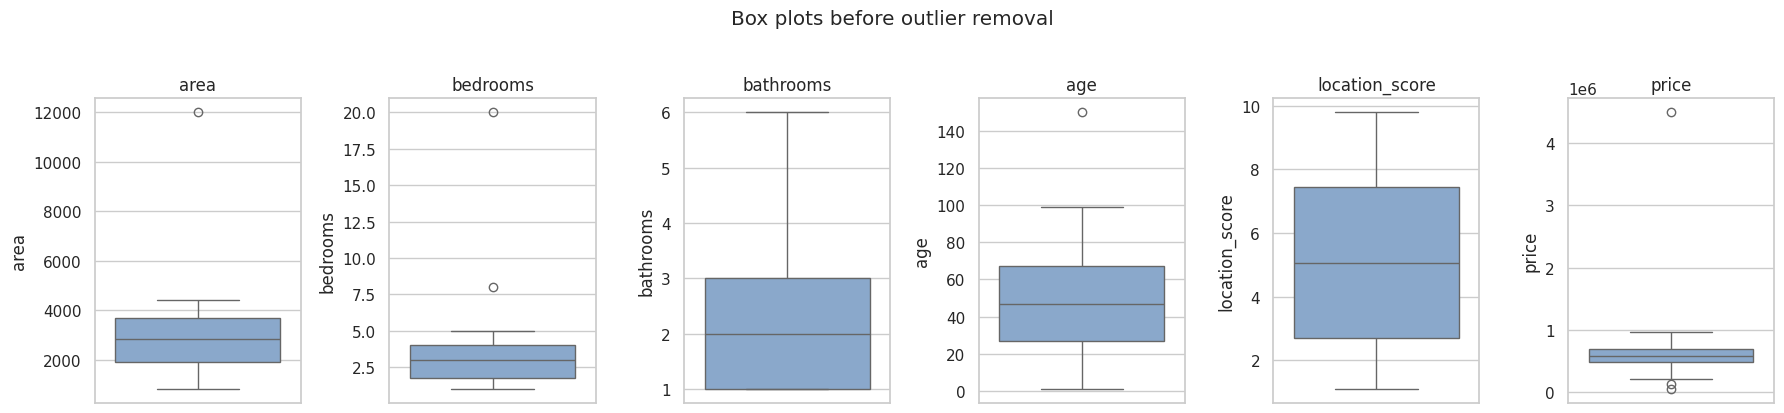

In [11]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="#7fa7d6")
    ax.set_title(col)
plt.suptitle("Box plots before outlier removal", y=1.03)
plt.tight_layout()
plt.show()

**Decision on the three flagged rows:**

**Row 5** — 12,000 sq ft, 8 bed, 6 bath, price 4,500,000. Every other house is below 4,500 sq ft and 1,000,000. It is a different market segment (a mansion) and a single point like this would dominate a least-squares fit.
**Row 15** — 20 bedrooms in a 3,971 sq ft house priced at 120,000, with bathrooms and age missing. Not physically credible — almost certainly a data-entry error.
**Row 42** — age 150 years, price 45,000 for a 3,547 sq ft house with a good location score. The price is far below anything comparable — likely an error.

These rows are removed so the model describes the typical housing stock rather than three anomalies. (In Stage 3 I show how much they would distort the model if kept.)

In [12]:
df_with_outliers = df.copy()          # kept for comparison later
df = df.drop(index=sorted(outlier_rows)).reset_index(drop=True)

# 3. impute remaining missing values with the median
for col in ["bathrooms", "age"]:
    med = df[col].median()
    df[col] = df[col].fillna(med)
    print(f"{col}: filled with median = {med}")

print("\nRows after cleaning:", len(df))
print("Missing values left:", df.isna().sum().sum())
df.describe().T

bathrooms: filled with median = 2.0
age: filled with median = 47.0

Rows after cleaning: 97
Missing values left: 0


,count,mean,std,min,25%,50%,75%,max
area,97.00,"2,753.95","1,059.31",821.00,"1,929.00","2,847.00","3,688.00","4,438.00"
bedrooms,97.00,2.97,1.48,1.00,1.00,3.00,4.00,5.00
bathrooms,97.00,1.99,0.80,1.00,1.00,2.00,3.00,3.00
age,97.00,49.14,27.71,1.00,29.00,47.00,66.00,99.00
location_score,97.00,5.23,2.70,1.10,2.70,5.00,7.30,9.80
price,97.00,"576,829.86","158,646.25","213,889.00","485,643.00","584,342.00","690,082.00","969,497.00"


## 1.5 Visual exploration

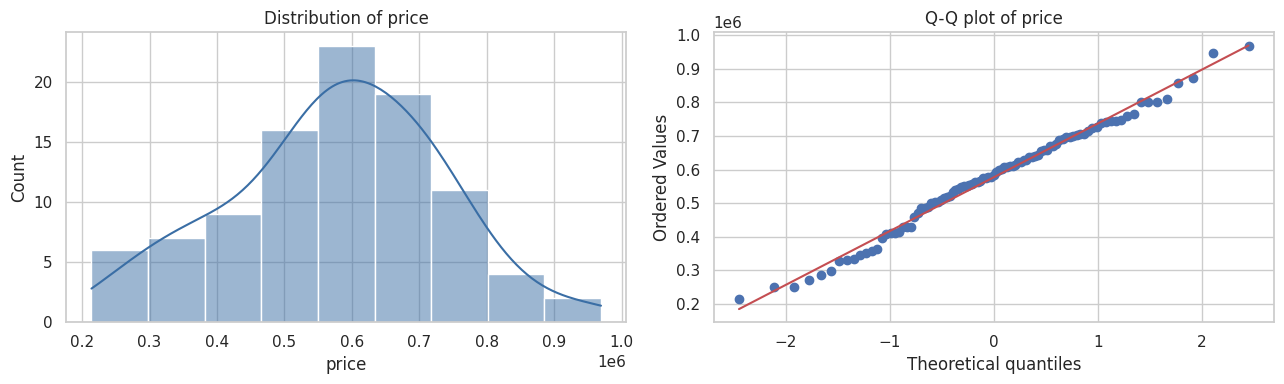

Skewness of price: -0.142


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["price"], kde=True, ax=axes[0], color="#3a6ea5")
axes[0].set_title("Distribution of price")
stats.probplot(df["price"], dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot of price")
plt.tight_layout()
plt.show()
print(f"Skewness of price: {df['price'].skew():.3f}")

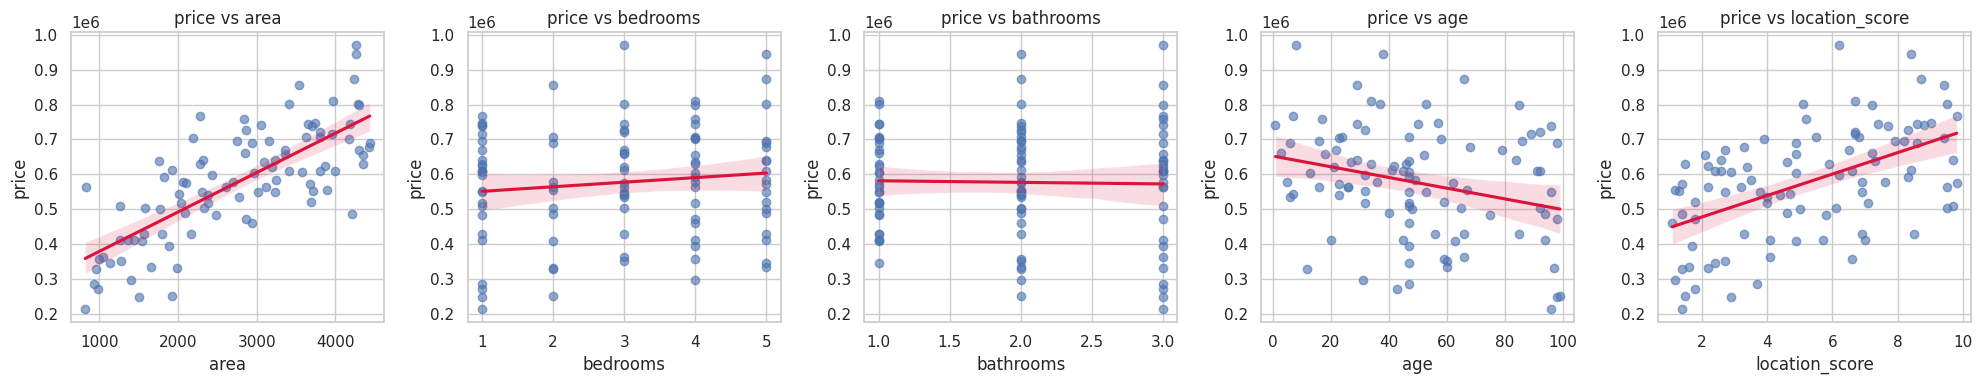

In [14]:
features_num = ["area", "bedrooms", "bathrooms", "age", "location_score"]
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, features_num):
    sns.regplot(data=df, x=col, y="price", ax=ax,
                scatter_kws={"alpha": 0.6}, line_kws={"color": "crimson"})
    ax.set_title(f"price vs {col}")
plt.tight_layout()
plt.show()

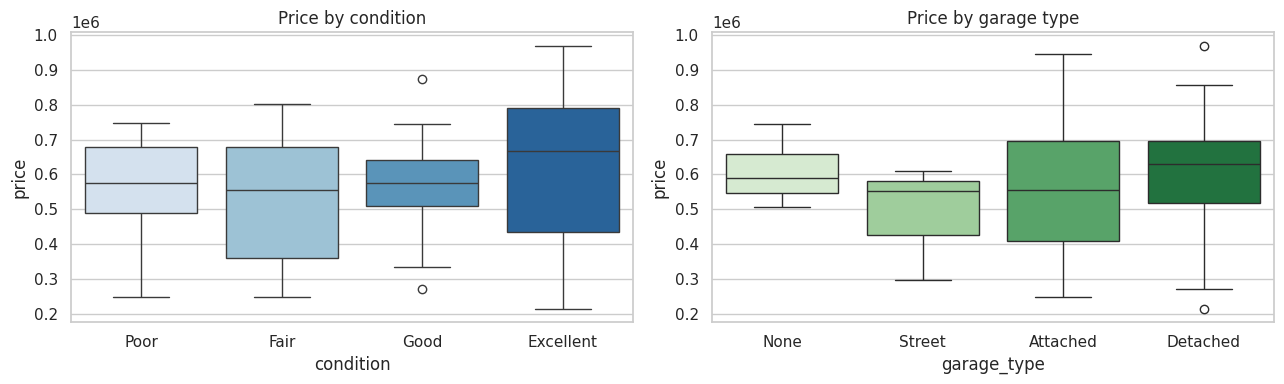

,count,mean,median
condition,,,
Poor,13,"572,409.00","576,635.00"
Fair,19,"538,074.95","555,429.00"
Good,47,"573,110.00","575,948.00"
Excellent,18,"630,643.61","666,709.00"


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order_cond = ["Poor", "Fair", "Good", "Excellent"]
sns.boxplot(data=df, x="condition", y="price", order=order_cond, ax=axes[0], palette="Blues")
axes[0].set_title("Price by condition")
sns.boxplot(data=df, x="garage_type", y="price", order=["None", "Street", "Attached", "Detached"],
            ax=axes[1], palette="Greens")
axes[1].set_title("Price by garage type")
plt.tight_layout()
plt.show()
df.groupby("condition")["price"].agg(["count", "mean", "median"]).reindex(order_cond)

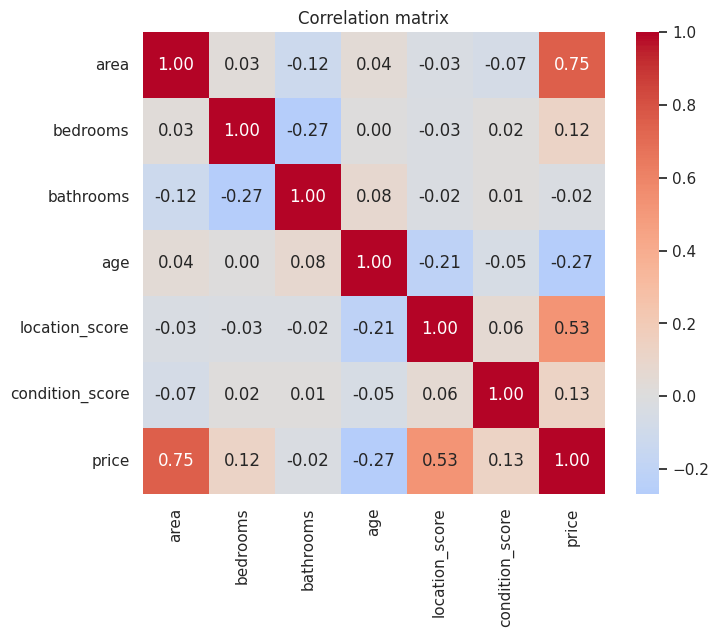

,price
area,0.75
location_score,0.53
condition_score,0.13
bedrooms,0.12
bathrooms,-0.02
age,-0.27


In [16]:
df["condition_score"] = df["condition"].map({"Poor": 0, "Fair": 1, "Good": 2, "Excellent": 3})

corr = df[features_num + ["condition_score", "price"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix")
plt.show()
corr["price"].drop("price").sort_values(ascending=False)

### Exploration findings

- After cleaning there are **97 houses**, no missing values, and prices range from about 214,000 to 969,000.
- `price` is close to normally distributed (skewness ≈ 0), so no log transformation is needed.
- **`area` is the strongest driver** (r ≈ 0.76), followed by **`location_score`** (r ≈ 0.53). Both relationships look linear in the scatter plots.
- **`age`** has a weak negative relationship (r ≈ −0.27): older houses sell for less.
- `bedrooms`, `bathrooms` and `condition` have weak simple correlations with price. They may still matter once area and location are held constant, which is what multiple regression measures.
- The predictors are almost uncorrelated with each other (all |r| small), an early sign that multicollinearity will not be a problem.

---
# Stage 2 — Build Model

## 2.1 Feature preparation

- **`condition`** is ordinal (Poor < Fair < Good < Excellent) → encoded as `condition_score` 0–3.
- **`garage_type`** is nominal → one-hot encoded with `drop_first=True` (reference category = **Attached**) to avoid the dummy-variable trap.

In [17]:
X = pd.get_dummies(df.drop(columns=["price", "condition"]),
                   columns=["garage_type"], drop_first=True, dtype=int)
y = df["price"]
print("Features:", X.columns.tolist())
X.head()

Features: ['area', 'bedrooms', 'bathrooms', 'age', 'location_score', 'condition_score', 'garage_type_Detached', 'garage_type_None', 'garage_type_Street']


,area,bedrooms,bathrooms,age,location_score,condition_score,garage_type_Detached,garage_type_None,garage_type_Street
0,3974,4,1.00,34.00,6.70,3,0,0,0
1,4307,1,2.00,79.00,2.70,1,1,0,0
2,1660,5,2.00,60.00,1.60,2,0,0,0
3,2094,5,2.00,40.00,4.60,0,0,0,0
4,1930,2,2.00,99.00,1.50,1,0,0,0


## 2.2 Train / test split (80 / 20)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (77, 9)  Test: (20, 9)


## 2.3 Fit the linear regression model

In [19]:
model = LinearRegression()
model.fit(X_train, y_train)

coef = pd.DataFrame({"coefficient": model.coef_}, index=X.columns)
print(f"Intercept: {model.intercept_:,.2f}")
coef.sort_values("coefficient", ascending=False)

Intercept: 23,302.55


,coefficient
location_score,"30,881.34"
bathrooms,"24,523.80"
condition_score,"17,431.13"
bedrooms,"15,405.18"
garage_type_Detached,"15,156.64"
area,117.41
age,"-1,175.00"
garage_type_Street,"-15,959.05"
garage_type_None,"-30,029.03"


In [20]:
terms = " + ".join(f"({c:,.1f} × {n})" for n, c in zip(X.columns, model.coef_))
print(f"price = {model.intercept_:,.1f} + {terms}")

price = 23,302.5 + (117.4 × area) + (15,405.2 × bedrooms) + (24,523.8 × bathrooms) + (-1,175.0 × age) + (30,881.3 × location_score) + (17,431.1 × condition_score) + (15,156.6 × garage_type_Detached) + (-30,029.0 × garage_type_None) + (-15,959.1 × garage_type_Street)


---
# Stage 3 — Test Model

## 3.1 Evaluation metrics: MSE, RMSE, R²

In [21]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "R²": r2_score(y_true, y_pred)}

results = pd.DataFrame({"Train": metrics(y_train, y_train_pred),
                        "Test": metrics(y_test, y_test_pred)}).T
results.style.format({"MSE": "{:,.0f}", "RMSE": "{:,.0f}", "R²": "{:.4f}"})

,MSE,RMSE,R²
Train,"1,012,758,388","31,824",0.9545
Test,"819,989,996","28,635",0.9764


In [22]:
# Baseline for context: always predict the mean training price
baseline_rmse = np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_train.mean())))
test_rmse = results.loc["Test", "RMSE"]
print(f"Baseline RMSE (predict the mean): {baseline_rmse:,.0f}")
print(f"Model RMSE:                       {test_rmse:,.0f}")
print(f"Error reduction vs baseline:      {(1 - test_rmse / baseline_rmse) * 100:.1f}%")
print(f"RMSE as % of mean price:          {test_rmse / y.mean() * 100:.1f}%")

Baseline RMSE (predict the mean): 187,790
Model RMSE:                       28,635
Error reduction vs baseline:      84.8%
RMSE as % of mean price:          5.0%


In [23]:
# With only 97 rows a single split can be lucky or unlucky, so confirm with 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_r2 = cross_val_score(LinearRegression(), X, y, cv=cv, scoring="r2")
cv_rmse = -cross_val_score(LinearRegression(), X, y, cv=cv, scoring="neg_root_mean_squared_error")
print("CV R² per fold:  ", np.round(cv_r2, 3))
print(f"Mean CV R²:       {cv_r2.mean():.3f} ± {cv_r2.std():.3f}")
print(f"Mean CV RMSE:     {cv_rmse.mean():,.0f}")

CV R² per fold:   [0.976 0.962 0.962 0.88  0.943]
Mean CV R²:       0.945 ± 0.034
Mean CV RMSE:     33,237


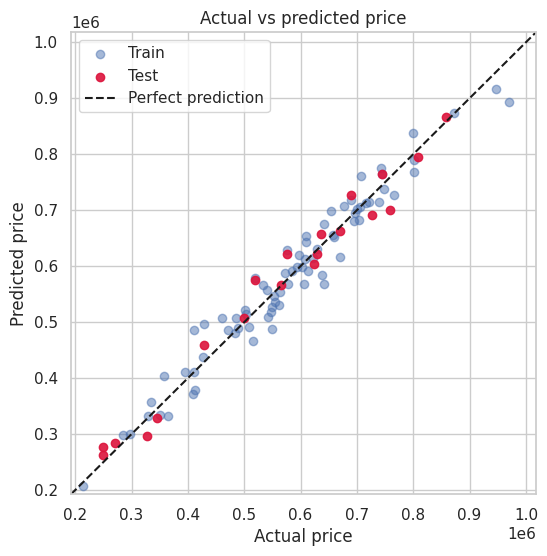

In [24]:
lims = [y.min() * 0.9, y.max() * 1.05]
plt.figure(figsize=(6, 6))
plt.scatter(y_train, y_train_pred, alpha=0.5, label="Train")
plt.scatter(y_test, y_test_pred, alpha=0.9, color="crimson", label="Test")
plt.plot(lims, lims, "k--", label="Perfect prediction")
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("Actual price"); plt.ylabel("Predicted price")
plt.title("Actual vs predicted price")
plt.legend()
plt.show()

### Interpretation of the evaluation metrics

- **MSE (≈ 820 million on the test set)** is the average squared prediction error. Because it is in *squared* currency units it is hard to read directly; it is mainly useful for comparing models (lower is better).
- **RMSE (≈ 28,600 on test)** is the square root of MSE, back in price units: a typical prediction is off by about **28,600**, roughly **5%** of the average house price (≈ 577,000). That is about **85% smaller** than the error of simply guessing the average price (≈ 188,000).
- **R² (≈ 0.976 on test, 0.954 on train)** means the model explains about **95–98% of the variation in house prices**. The 5-fold cross-validated R² averages about **0.94**, which is the more reliable estimate given the small dataset.
- **No overfitting:** train and test scores are very close (the test score is slightly higher, which with only 20 test houses is simply sampling luck — cross-validation confirms performance in the 0.88–0.98 range). In the actual-vs-predicted plot the points sit tightly along the diagonal.

## 3.2 Checking the linear regression assumptions

Residuals (actual − predicted) from the training set are used for the diagnostics.

In [25]:
residuals = y_train - y_train_pred
fitted = y_train_pred

### Assumption 1 — Linearity

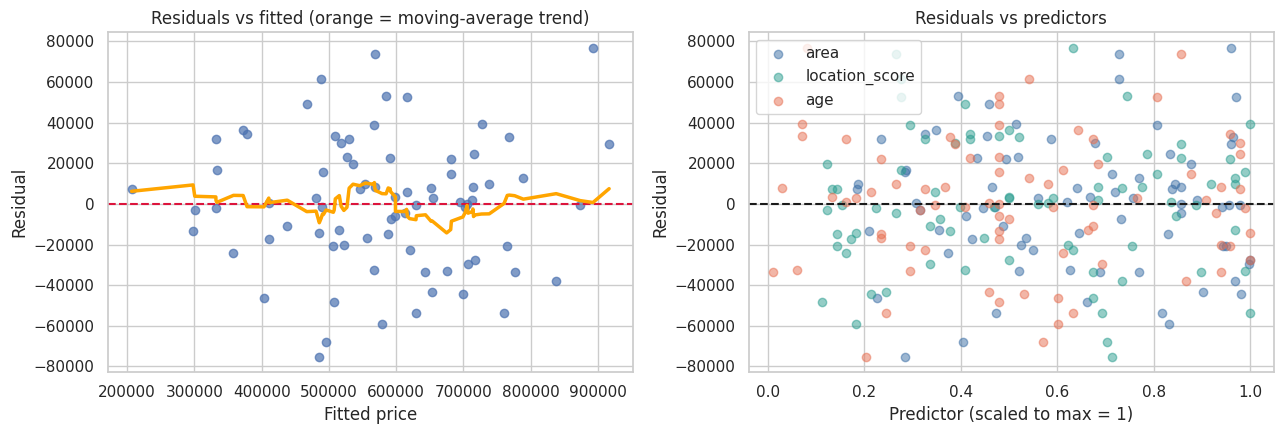

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(fitted, residuals, alpha=0.7)
axes[0].axhline(0, color="crimson", ls="--")
trend_line(axes[0], fitted, residuals, color="orange")
axes[0].set_xlabel("Fitted price"); axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs fitted (orange = moving-average trend)")

# residuals against each main numeric predictor
for col, c in zip(["area", "location_score", "age"], ["#3a6ea5", "#2a9d8f", "#e76f51"]):
    axes[1].scatter(X_train[col] / X_train[col].max(), residuals, alpha=0.5, label=col, color=c)
axes[1].axhline(0, color="k", ls="--")
axes[1].set_xlabel("Predictor (scaled to max = 1)"); axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs predictors")
axes[1].legend()
plt.tight_layout()
plt.show()

### Assumption 2 — No multicollinearity (Variance Inflation Factor)



In [27]:
def vif_table(frame):
    out = {}
    for col in frame.columns:
        others = frame.drop(columns=col)
        r2 = LinearRegression().fit(others, frame[col]).score(others, frame[col])
        out[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.DataFrame({"VIF": out}).sort_values("VIF", ascending=False)

vif = vif_table(X)
vif

,VIF
garage_type_Detached,1.27
garage_type_None,1.21
age,1.16
location_score,1.15
garage_type_Street,1.12
bathrooms,1.11
bedrooms,1.11
area,1.10
condition_score,1.09


### Assumption 3 — Normality of errors

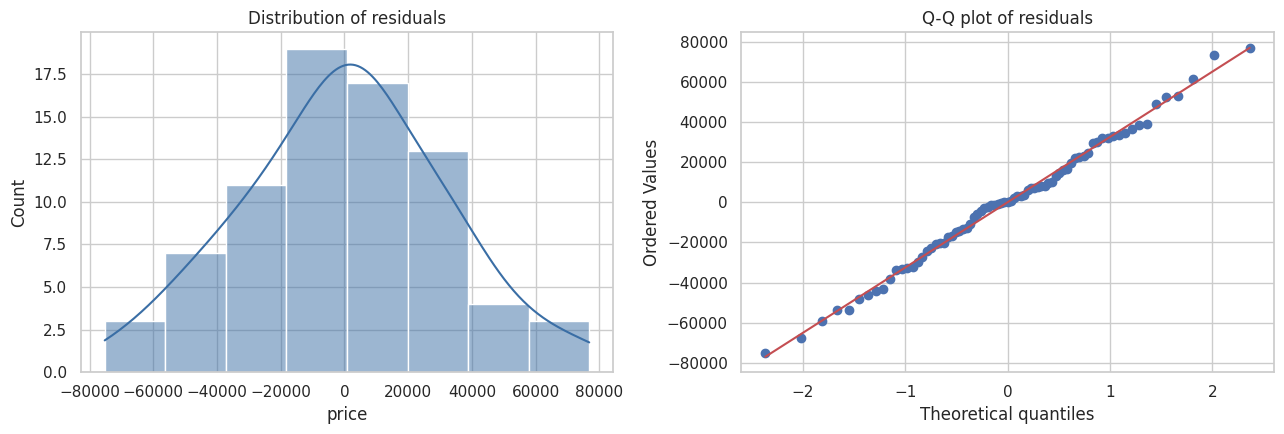

Shapiro-Wilk: W = 0.9932, p-value = 0.9589
Residual skewness = 0.008, kurtosis = -0.153


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(residuals, kde=True, ax=axes[0], color="#3a6ea5")
axes[0].set_title("Distribution of residuals")
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot of residuals")
plt.tight_layout()
plt.show()

sw_stat, sw_p = stats.shapiro(residuals)
print(f"Shapiro-Wilk: W = {sw_stat:.4f}, p-value = {sw_p:.4f}")
print(f"Residual skewness = {stats.skew(residuals):.3f}, kurtosis = {stats.kurtosis(residuals):.3f}")

### Assumption 4 — Independence of errors (Durbin-Watson)

DW ranges 0–4: ≈ 2 means no autocorrelation; < 1.5 suggests positive and > 2.5 negative autocorrelation.

Durbin-Watson statistic: 2.060


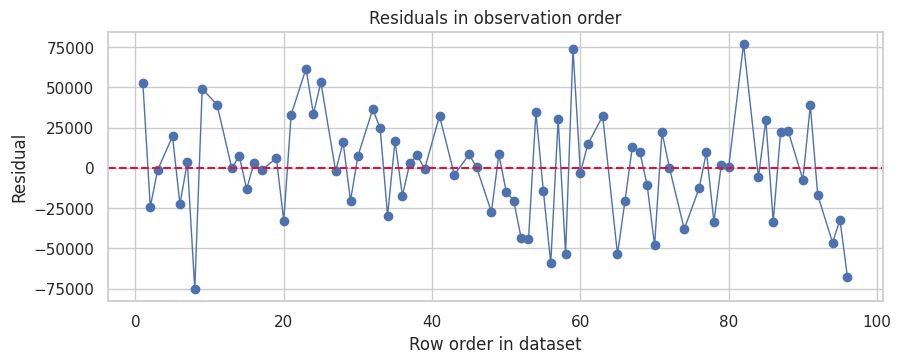

In [29]:
r = residuals.sort_index().values          # residuals in original row order
dw = np.sum(np.diff(r) ** 2) / np.sum(r ** 2)
print(f"Durbin-Watson statistic: {dw:.3f}")

plt.figure(figsize=(10, 3.5))
plt.plot(residuals.sort_index().index, r, marker="o", lw=1)
plt.axhline(0, color="crimson", ls="--")
plt.xlabel("Row order in dataset"); plt.ylabel("Residual")
plt.title("Residuals in observation order")
plt.show()

### Assumption 5 — Homoscedasticity (constant error variance, Breusch-Pagan test)

Breusch-Pagan regresses the squared residuals on the features. LM = n·R² follows a χ² distribution with k degrees of freedom. H₀: constant variance.

Breusch-Pagan LM = 8.108, p-value = 0.5233


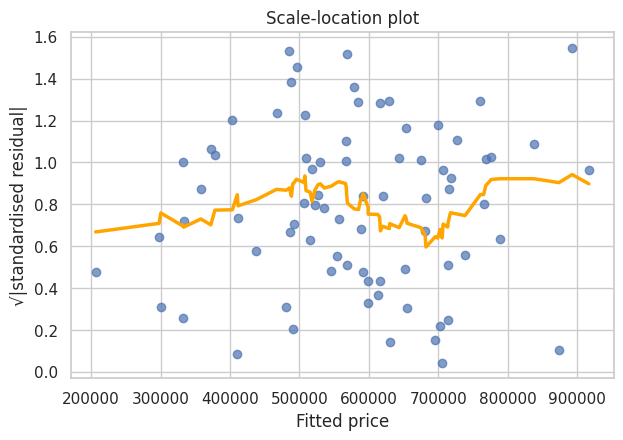

In [30]:
aux = LinearRegression().fit(X_train, residuals ** 2)
lm_stat = len(residuals) * aux.score(X_train, residuals ** 2)
bp_p = stats.chi2.sf(lm_stat, df=X_train.shape[1])
print(f"Breusch-Pagan LM = {lm_stat:.3f}, p-value = {bp_p:.4f}")

plt.figure(figsize=(7, 4.5))
plt.scatter(fitted, np.sqrt(np.abs(residuals / residuals.std())), alpha=0.7)
trend_line(plt.gca(), fitted, np.sqrt(np.abs(residuals / residuals.std())), color="orange")
plt.xlabel("Fitted price"); plt.ylabel("√|standardised residual|")
plt.title("Scale-location plot")
plt.show()

## 3.3 Why the cleaning mattered — same model with the outliers kept

In [31]:
d = df_with_outliers.copy()
for col in ["bathrooms", "age"]:
    d[col] = d[col].fillna(d[col].median())
d["condition_score"] = d["condition"].map({"Poor": 0, "Fair": 1, "Good": 2, "Excellent": 3})
Xo = pd.get_dummies(d.drop(columns=["price", "condition"]), columns=["garage_type"],
                    drop_first=True, dtype=int)[X.columns]
yo = d["price"]

cv_r2_o = cross_val_score(LinearRegression(), Xo, yo, cv=cv, scoring="r2")
cv_rmse_o = -cross_val_score(LinearRegression(), Xo, yo, cv=cv, scoring="neg_root_mean_squared_error")
pd.DataFrame({"Mean CV R²": [cv_r2.mean(), cv_r2_o.mean()],
              "Mean CV RMSE": [cv_rmse.mean(), cv_rmse_o.mean()]},
             index=["Cleaned data (97 rows)", "Outliers kept (100 rows)"])

,Mean CV R²,Mean CV RMSE
Cleaned data (97 rows),0.94,"33,236.73"
Outliers kept (100 rows),-0.06,"248,536.16"


Keeping just three bad rows collapses the model: mean cross-validated R² falls from about **0.94 to roughly −0.06** (worse than predicting the average) and RMSE grows from about **33,000 to about 249,000**. This is a clear demonstration that linear regression (least squares) is very sensitive to outliers, and that the exploration stage directly determines model quality.

The data was cleaned by correcting price formats and labels, imputing 13 missing values, and removing 3 outliers, leaving 97 records. The model achieved a test RMSE of approximately 28,600, test R² of 0.976, and cross-validation R² of 0.94, satisfying the key regression assumptions. Area and location score were the strongest price predictors, while age reduced value and condition, rooms, and garage type had smaller effects. However, the small dataset and varying cross-validation scores (0.88–0.98) limit reliability. Future improvements should include collecting more data and testing Ridge/Lasso regression and interaction terms. Predictions should remain within the observed data range.
